In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from zipfile import ZipFile
import os

zip_path = "/content/drive/MyDrive/Defense/Final/Retinopathy.zip"          # Path of your ZIP file
extract_to = "/content/drive/MyDrive/Defense/Final/FinalDataSet"         # Folder where you want to unzip

# Create the folder if it doesn’t exist
os.makedirs(extract_to, exist_ok=True)

# Unzip
with ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print("Unzipped successfully to:", extract_to)

Unzipped successfully to: /content/drive/MyDrive/Defense/Final/FinalDataSet


In [14]:
# --- imports ---
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# image processing
import cv2
from tqdm import tqdm

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix as sk_confusion_matrix
from sklearn.metrics import classification_report
from sklearn import metrics

# tensorflow / keras
import tensorflow as tf
from tensorflow import keras

# utilities
from time import perf_counter

In [16]:
image_dir = Path('/content/drive/MyDrive/Defense/Final/FinalDataSet/Dataset')
filepaths = list(image_dir.glob(r'**/*/*'))
labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1], filepaths))

In [17]:
filepaths = pd.Series(filepaths, name='Filepath').astype(str)
labels = pd.Series(labels, name='Label')

# Concatenate filepaths and labels
image_df = pd.concat([filepaths, labels], axis=1)

# Shuffle the DataFrame and reset index
image_df = image_df.sample(frac=1).reset_index(drop = True)

# Show the result
image_df.head(5)

,Filepath,Label
0,/content/drive/MyDrive/Defense/Final/FinalData...,No_DR
1,/content/drive/MyDrive/Defense/Final/FinalData...,Proliferate_DR
2,/content/drive/MyDrive/Defense/Final/FinalData...,Moderate
3,/content/drive/MyDrive/Defense/Final/FinalData...,Severe
4,/content/drive/MyDrive/Defense/Final/FinalData...,No_DR


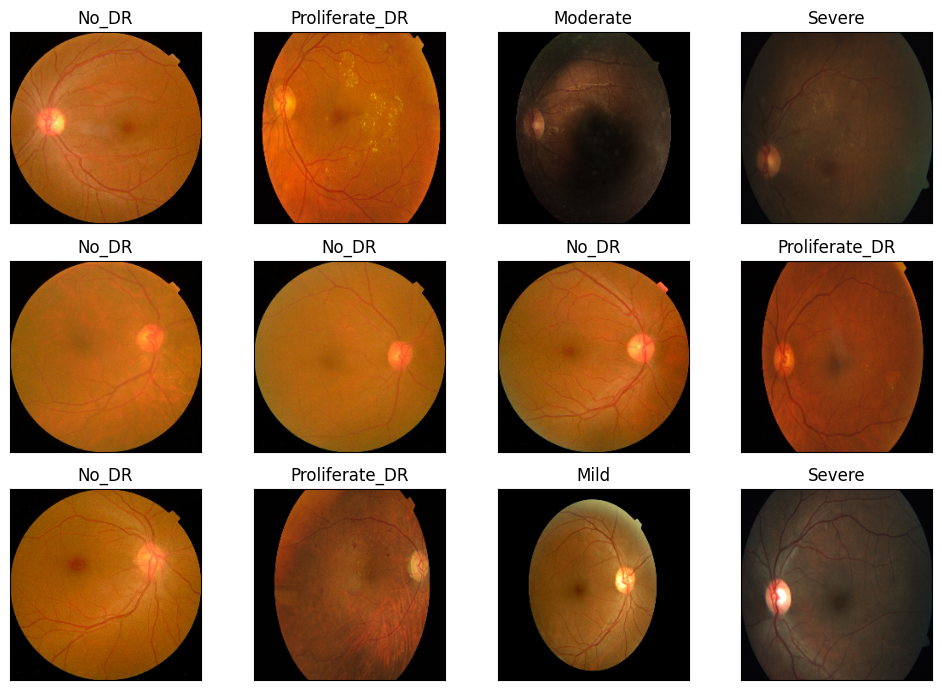

In [18]:
# Display some pictures of the dataset with their labels
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(10, 7),
                        subplot_kw={'xticks': [], 'yticks': []})

for i, ax in enumerate(axes.flat):

    ax.imshow(plt.imread(image_df.Filepath[i]))
    ax.set_title(image_df.Label[i])
plt.tight_layout()
plt.show()

In [19]:
# Class distribution
vc = image_df['Label'].value_counts()
print(vc)

Label
Proliferate_DR    1089
No_DR              968
Severe             575
Mild               527
Moderate           395
Name: count, dtype: int64


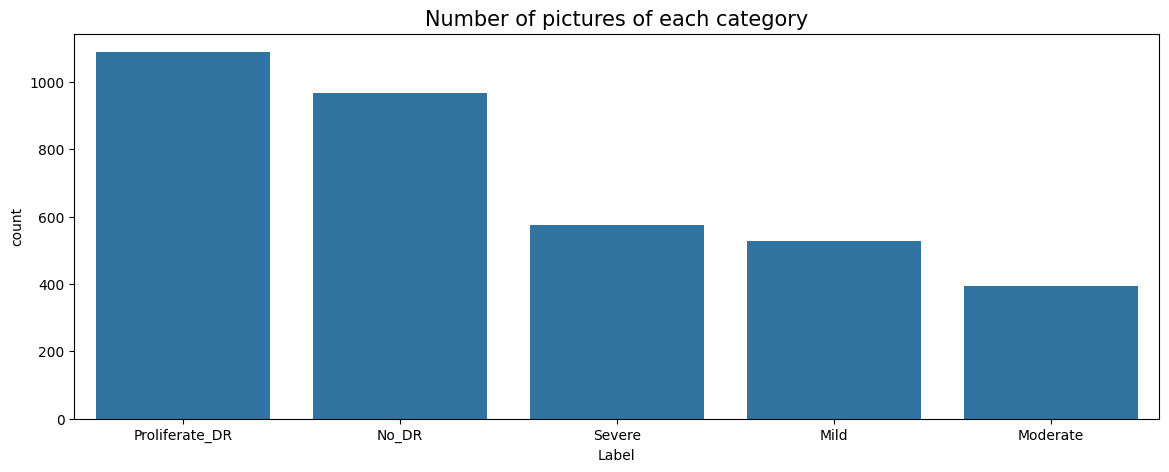

In [20]:
# Display the number of pictures of each category
vc = image_df['Label'].value_counts()
plt.figure(figsize=(14,5))
sns.barplot(x = vc.index, y = vc)
plt.title("Number of pictures of each category", fontsize = 15)
plt.show()

/tmp/ipython-input-1312477662.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=image_df, palette='coolwarm')


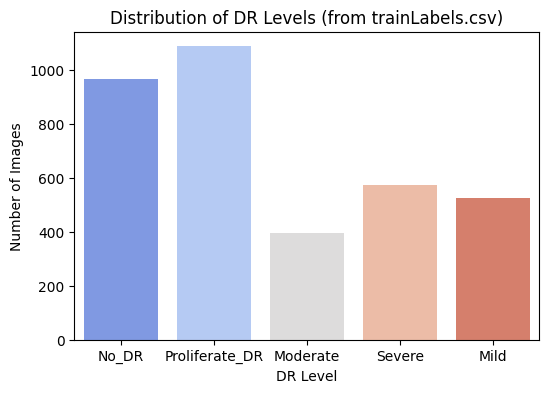

In [21]:
plt.figure(figsize=(6,4))

sns.countplot(x='Label', data=image_df, palette='coolwarm')

plt.title("Distribution of DR Levels (from trainLabels.csv)")
plt.xlabel("DR Level")
plt.ylabel("Number of Images")

plt.show()

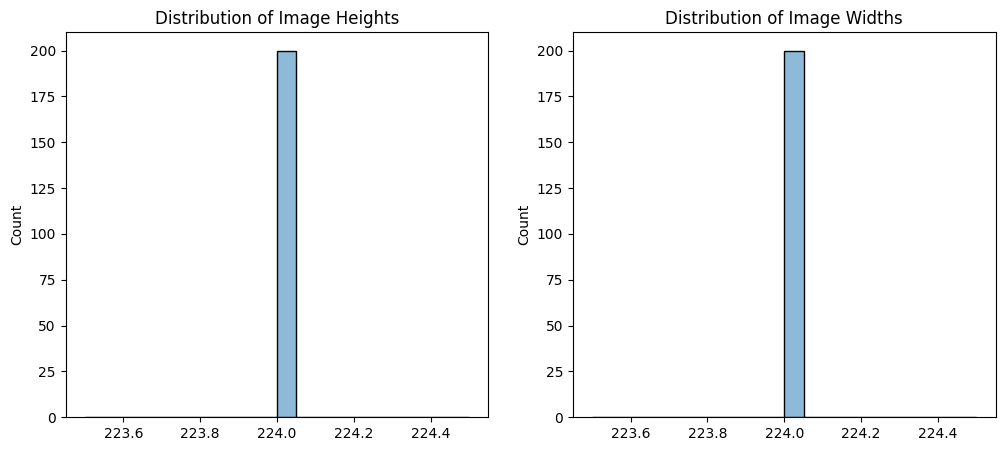

In [22]:
sample_per_class = 40

classes = image_df['Label'].unique().tolist()
data_path = image_dir

img_shapes = []
brightness = []

for cls in classes:
    folder = os.path.join(data_path, cls)
    if not os.path.isdir(folder):
        continue
    files = os.listdir(folder)[:sample_per_class]
    for img_file in files:
        img_path = os.path.join(folder, img_file)
        img = cv2.imread(img_path)
        if img is not None:
            img_shapes.append(img.shape[:2])  # (height, width)
            brightness.append(np.mean(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)))

if len(img_shapes) > 0:
    heights = [s[0] for s in img_shapes]
    widths = [s[1] for s in img_shapes]
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    sns.histplot(heights, bins=20, kde=True)
    plt.title("Distribution of Image Heights")

    plt.subplot(1,2,2)
    sns.histplot(widths, bins=20, kde=True)
    plt.title("Distribution of Image Widths")
    plt.show()
else:
    print("No image shapes collected (check folders).")

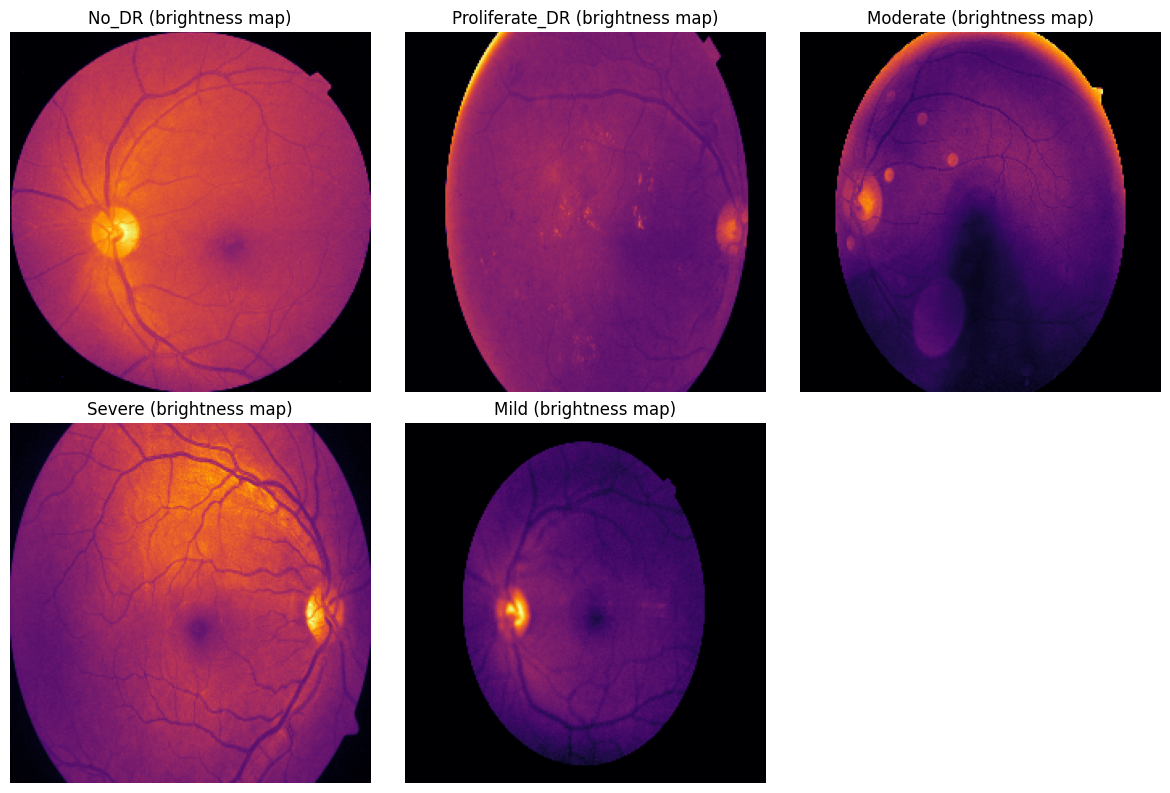

In [23]:
# Brightness heatmaps: display one resized greyscale heatmap per class (if available)
plt.figure(figsize=(12,8))
sampled_imgs = []
for cls in classes:
    folder = os.path.join(data_path, cls)
    if not os.path.isdir(folder):
        continue
    filelist = os.listdir(folder)
    if len(filelist) == 0:
        continue
    sample_img_path = os.path.join(folder, filelist[0])
    img = cv2.imread(sample_img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        continue
    img = cv2.resize(img, (224, 224))
    sampled_imgs.append((cls, img))

for i, (cls, img) in enumerate(sampled_imgs):
    plt.subplot(2, int(np.ceil(len(sampled_imgs)/2)), i+1)
    plt.imshow(img, cmap='inferno')
    plt.title(f"{cls} (brightness map)")
    plt.axis('off')

plt.tight_layout()
plt.show()


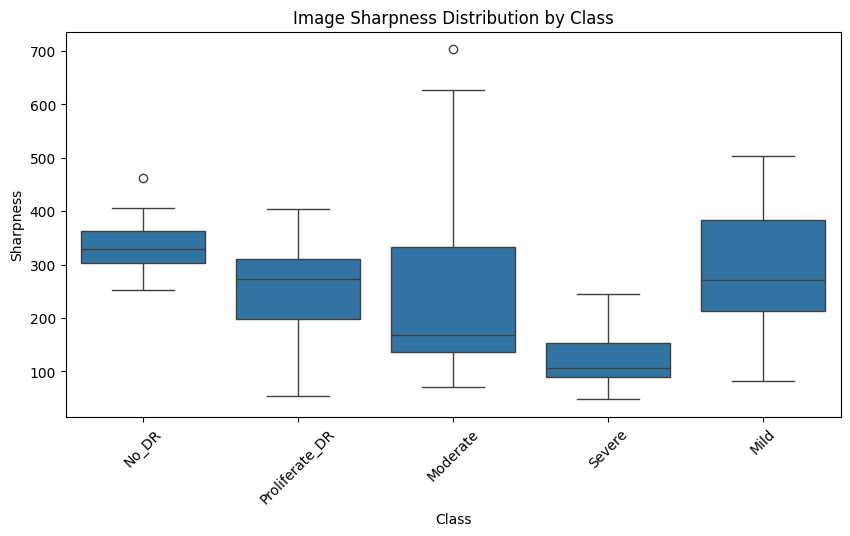

In [24]:
# Sharpness boxplot (Laplacian variance)
sharpness = []
sharp_per_class = 30
for cls in classes:
    folder = os.path.join(data_path, cls)
    if not os.path.isdir(folder):
        continue
    files = os.listdir(folder)[:sharp_per_class]
    for img_file in files:
        img = cv2.imread(os.path.join(folder, img_file), cv2.IMREAD_GRAYSCALE)
        if img is not None:
            lap_var = cv2.Laplacian(img, cv2.CV_64F).var()
            sharpness.append((cls, lap_var))

if len(sharpness) > 0:
    sharp_df = pd.DataFrame(sharpness, columns=['Class', 'Sharpness'])
    plt.figure(figsize=(10,5))
    sns.boxplot(data=sharp_df, x='Class', y='Sharpness')
    plt.title("Image Sharpness Distribution by Class")
    plt.xticks(rotation=45)
    plt.show()
else:
    print("No sharpness data collected.")

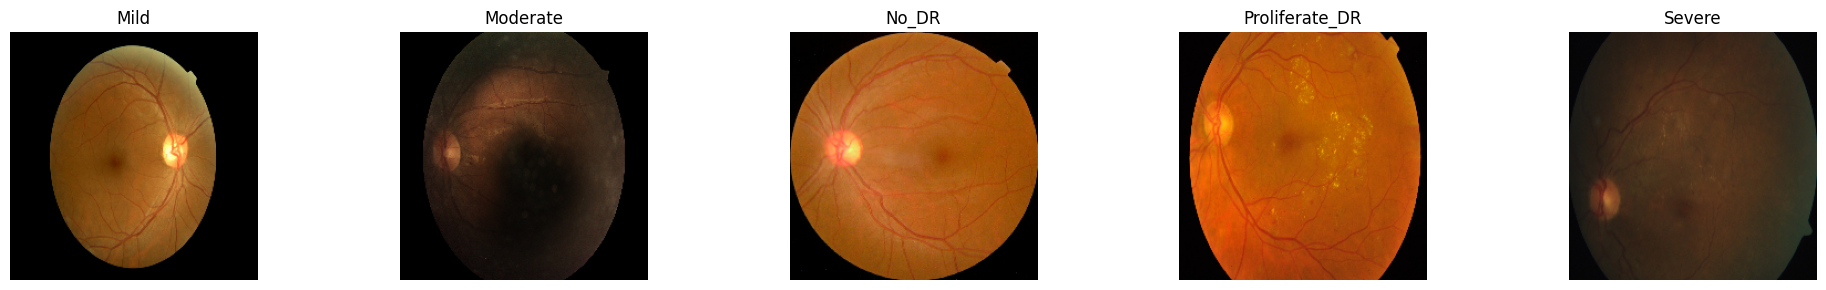

In [25]:
# -------------------------
# Small helper to show sample images for each class
# -------------------------
def show_one_sample_per_class(df, folder):
    unique_labels = sorted(df['Label'].unique())
    n = len(unique_labels)
    cols = min(5, n)
    rows = int(np.ceil(n/cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 3*rows))
    axes = axes.flat if n > 1 else [axes]
    idx = 0
    for cls in unique_labels:
        axes[idx].set_title(cls)
        try:
            sample = df[df['Label']==cls].iloc[0]
            img = cv2.imread(sample['Filepath'])
            if img is None:
                axes[idx].text(0.5, 0.5, "Not readable", ha='center')
            else:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                axes[idx].imshow(img)
            axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, "No image", ha='center')
        idx += 1
    for j in range(idx, rows*cols):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()

show_one_sample_per_class(image_df, data_path)

In [26]:
# -------------------------
# Train/test split and generators
# -------------------------
train_df, test_df = train_test_split(image_df, train_size=0.8, shuffle=True, random_state=1)

In [27]:
# create a small validation split through ImageDataGenerator's validation_split

BATCH_SIZE = 16
IMG_SIZE = (224, 224)

def create_gen(train_df, test_df, batch_size=BATCH_SIZE):
    train_generator = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input,
        validation_split=0.1,
        rotation_range=20,
        width_shift_range=0.1,
        height_shift_range=0.1,
        horizontal_flip=True,
        zoom_range=0.1
    )

    test_generator = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=tf.keras.applications.mobilenet_v2.preprocess_input
    )

    train_images = train_generator.flow_from_dataframe(
        dataframe=train_df,
        x_col='Filepath',
        y_col='Label',
        target_size=IMG_SIZE,
        color_mode='rgb',
        class_mode='categorical',
        batch_size=batch_size,
        shuffle=True,
        subset='training'
    )

    val_images = train_generator.flow_from_dataframe(
        dataframe=train_df,
        x_col='Filepath',
        y_col='Label',
        target_size=IMG_SIZE,
        color_mode='rgb',
        class_mode='categorical',
        batch_size=batch_size,
        shuffle=True,
        subset='validation'
    )

    test_images = test_generator.flow_from_dataframe(
        dataframe=test_df,
        x_col='Filepath',
        y_col='Label',
        target_size=IMG_SIZE,
        color_mode='rgb',
        class_mode='categorical',
        batch_size=batch_size,
        shuffle=False
    )

    return train_generator, test_generator, train_images, val_images, test_images

train_generator, test_generator, train_images, val_images, test_images = create_gen(train_df, test_df, BATCH_SIZE)

Found 2559 validated image filenames belonging to 5 classes.
Found 284 validated image filenames belonging to 5 classes.
Found 711 validated image filenames belonging to 5 classes.


In [28]:
# -------------------------
# Model builder
# -------------------------
def get_model(base_model_fn, num_classes=len(classes)):
    kwargs = {
        'input_shape': (IMG_SIZE[0], IMG_SIZE[1], 3),
        'include_top': False,
        'weights': 'imagenet',
        'pooling': 'avg'
    }
    base = base_model_fn(**kwargs)
    base.trainable = False

    inputs = base.input
    x = tf.keras.layers.Dense(256, activation='relu')(base.output)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

In [29]:
# -------------------------
# Models to try
# -------------------------
models_info = {
    "DenseNet201": {"model_fn": tf.keras.applications.DenseNet201, "perf":0},
    "InceptionResNetV2": {"model_fn": tf.keras.applications.InceptionResNetV2, "perf":0},
    "Xception": {"model_fn": tf.keras.applications.Xception, "perf":0},
    "VGG16": {"model_fn": tf.keras.applications.VGG16, "perf":0},
    "ResNet50": {"model_fn": tf.keras.applications.ResNet50, "perf":0},
}



DenseNet201 Model Training Started ===>>>
74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 173s 784ms/step - accuracy: 0.7360 - loss: 0.7554 - val_accuracy: 0.9824 - val_loss: 0.0731
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 51s 319ms/step - accuracy: 0.9524 - loss: 0.1679 - val_accuracy: 0.9754 - val_loss: 0.0923
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 51s 316ms/step - accuracy: 0.9627 - loss: 0.1190 - val_accuracy: 0.9542 - val_loss: 0.1231
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 55s 344ms/step - accuracy: 0.9646 - loss: 0.1285 - val_accuracy: 0.9718 - val_loss: 0.0624
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 51s 321ms/step - accuracy: 0.9665 - loss: 0.1113 - val_accuracy: 0.9894 - val_loss: 0.0384
Epoch 6/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 310ms/step - accuracy: 0.9789 - loss: 0.0787 - val_accuracy: 0.9894 - val_loss: 0.0332
Epoch 7/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 83s 319ms/step - accuracy: 0.9753 - loss: 0.0884 - val_accuracy: 0.9824 - val_loss: 0.0588
Epoch 8/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 51s 316ms/step - accuracy: 0.9690 - loss: 

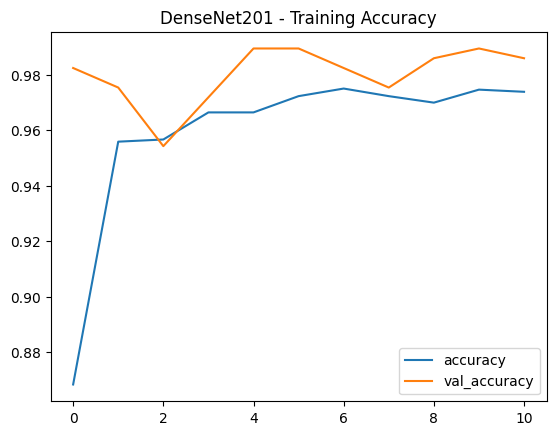

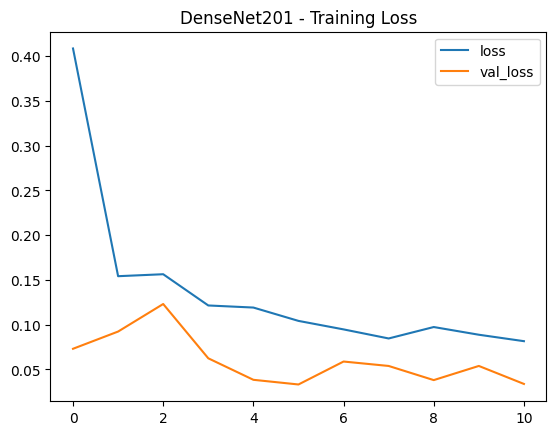



Accuracy on the test set: 97.47%
Accuracy: 0.97468
Precision: 0.97496
Recall: 0.97468
F1 Score: 0.97464
                precision    recall  f1-score   support

          Mild       0.96      0.99      0.97        94
      Moderate       0.99      0.99      0.99        79
         No_DR       0.96      0.99      0.98       187
Proliferate_DR       0.98      0.96      0.97       237
        Severe       0.99      0.96      0.97       114

      accuracy                           0.97       711
     macro avg       0.98      0.98      0.98       711
  weighted avg       0.97      0.97      0.97       711



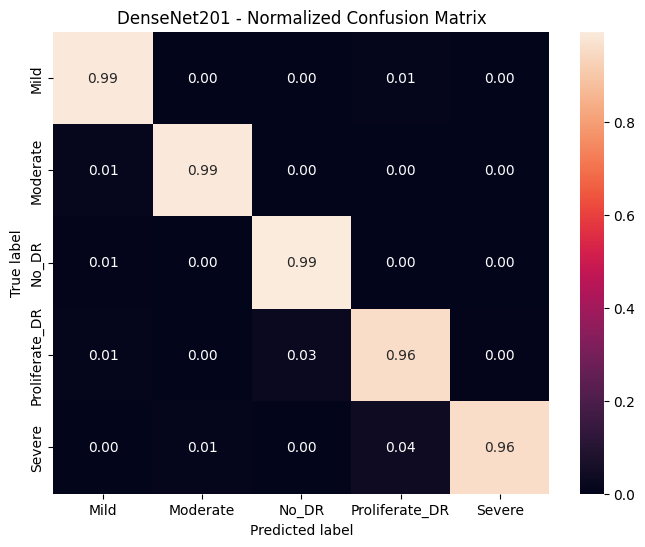

Performance (averaged across classes):
Rec (TPR avg)=  97.7060427749372
Spe (TNR avg)=  99.32704791276873
Pre (PPV avg)=  97.58385190938365
FPR avg=        0.6729520872312769
FNR avg=        2.2939572250628126
NPV avg=        99.31324521633913
FDR avg=        2.4161480906163346



InceptionResNetV2 Model Training Started ===>>>
219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 118s 541ms/step - accuracy: 0.5024 - loss: 1.3752 - val_accuracy: 0.9190 - val_loss: 0.2587
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 51s 321ms/step - accuracy: 0.8462 - loss: 0.4467 - val_accuracy: 0.9648 - val_loss: 0.1735
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 315ms/step - accuracy: 0.8668 - loss: 0.3837 - val_accuracy: 0.9366 - val_loss: 0.1980
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 315ms/step - accuracy: 0.8730 - loss: 0.3625 - val_accuracy: 0.9507 - val_loss: 0.1823
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 310ms/step - accuracy: 0.8482 - loss: 0.4157 - v

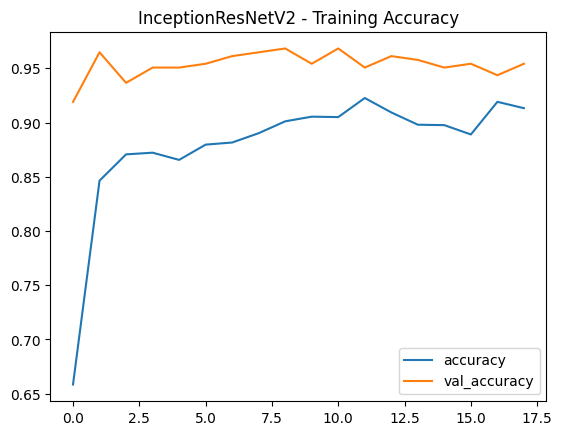

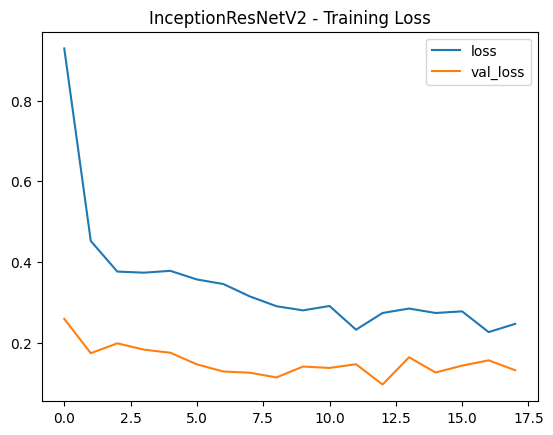



Accuracy on the test set: 94.37%
Accuracy: 0.94374
Precision: 0.94537
Recall: 0.94374
F1 Score: 0.94372
                precision    recall  f1-score   support

          Mild       0.86      0.95      0.90        94
      Moderate       0.94      0.85      0.89        79
         No_DR       0.99      0.99      0.99       187
Proliferate_DR       0.93      0.96      0.95       237
        Severe       0.97      0.90      0.94       114

      accuracy                           0.94       711
     macro avg       0.94      0.93      0.93       711
  weighted avg       0.95      0.94      0.94       711



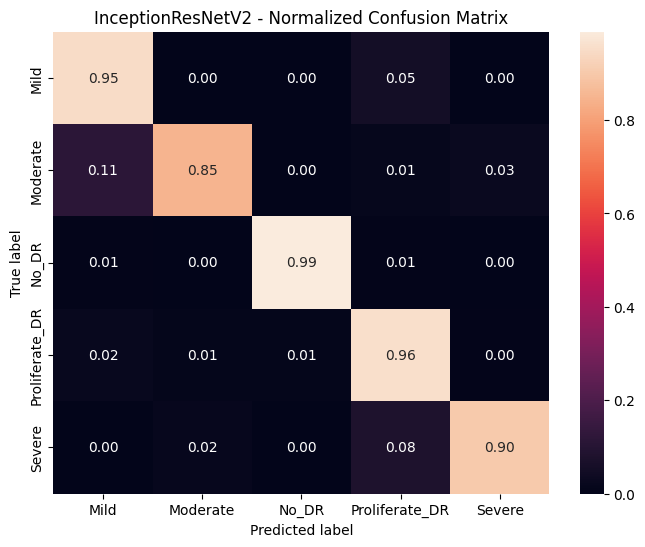

Performance (averaged across classes):
Rec (TPR avg)=  92.91058536796255
Spe (TNR avg)=  98.53525018297657
Pre (PPV avg)=  93.89181014485622
FPR avg=        1.4647498170234166
FNR avg=        7.089414632037447
NPV avg=        98.5929326853516
FDR avg=        6.108189855143769



Xception Model Training Started ===>>>
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 102s 507ms/step - accuracy: 0.6890 - loss: 0.7884 - val_accuracy: 0.9613 - val_loss: 0.1306
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 311ms/step - accuracy: 0.9353 - loss: 0.2258 - val_accuracy: 0.9507 - val_loss: 0.1322
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 48s 302ms/step - accuracy: 0.9292 - loss: 0.2061 - val_accuracy: 0.9789 - val_loss: 0.0808
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 49s 308ms/step - accuracy: 0.9493 - loss: 0.1700 - val_accuracy: 0.9789 - val_loss: 0.0663
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 49s 306ms/step - accuracy: 0.9495 - loss: 0.1616 - val_accuracy: 

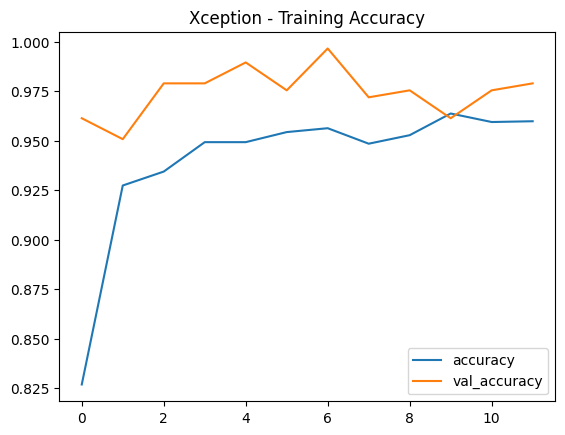

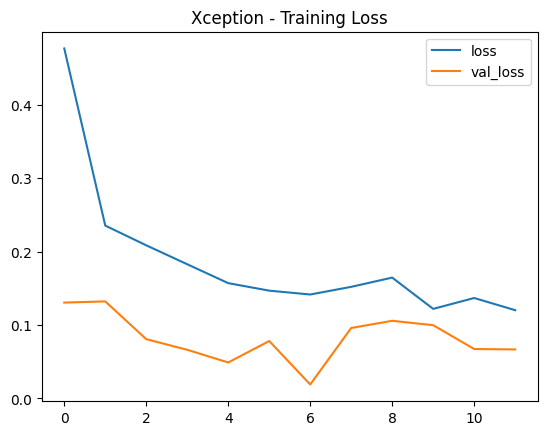



Accuracy on the test set: 94.51%
Accuracy: 0.94515
Precision: 0.94918
Recall: 0.94515
F1 Score: 0.94578
                precision    recall  f1-score   support

          Mild       0.82      0.99      0.90        94
      Moderate       0.91      0.91      0.91        79
         No_DR       0.98      0.98      0.98       187
Proliferate_DR       0.98      0.92      0.95       237
        Severe       0.96      0.92      0.94       114

      accuracy                           0.95       711
     macro avg       0.93      0.95      0.94       711
  weighted avg       0.95      0.95      0.95       711



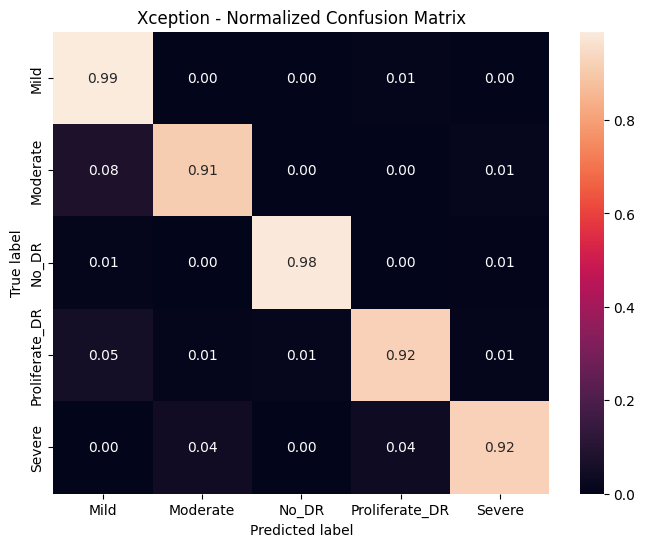

Performance (averaged across classes):
Rec (TPR avg)=  94.51190363299855
Spe (TNR avg)=  98.67070516446566
Pre (PPV avg)=  93.18479403004103
FPR avg=        1.3292948355343412
FNR avg=        5.488096367001461
NPV avg=        98.55284053296153
FDR avg=        6.815205969958979



VGG16 Model Training Started ===>>>
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 76s 406ms/step - accuracy: 0.5560 - loss: 1.1429 - val_accuracy: 0.9577 - val_loss: 0.1618
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 311ms/step - accuracy: 0.9204 - loss: 0.2644 - val_accuracy: 0.9542 - val_loss: 0.1219
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 49s 309ms/step - accuracy: 0.9258 - loss: 0.2262 - val_accuracy: 0.9754 - val_loss: 0.0979
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 310ms/step - accuracy: 0.9535 - loss: 0.1764 - val_accuracy: 0.9754 - val_loss: 0.0767
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 313ms/step - accuracy: 0.9542 - loss: 0.1643 - val_accuracy: 0.9

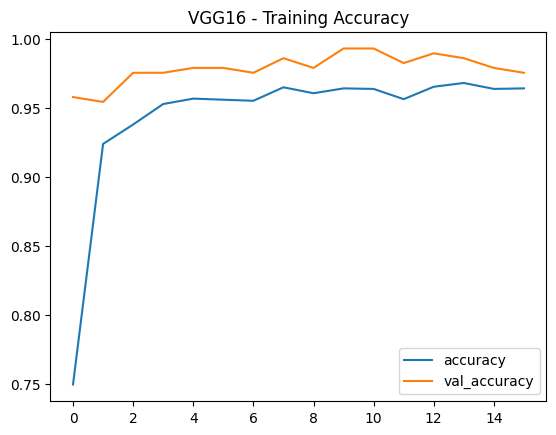

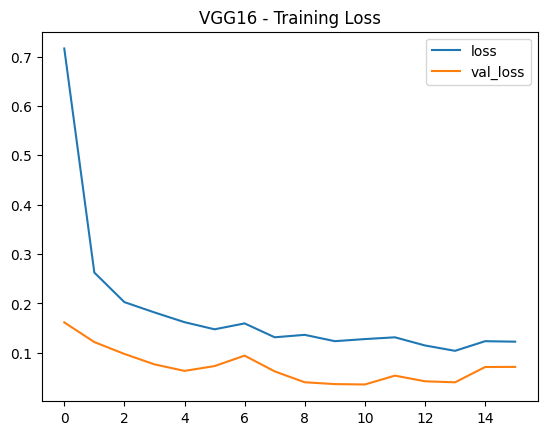



Accuracy on the test set: 96.20%
Accuracy: 0.96203
Precision: 0.96397
Recall: 0.96203
F1 Score: 0.9622
                precision    recall  f1-score   support

          Mild       0.90      0.99      0.94        94
      Moderate       0.87      0.91      0.89        79
         No_DR       0.99      0.99      0.99       187
Proliferate_DR       0.98      0.97      0.98       237
        Severe       1.00      0.89      0.94       114

      accuracy                           0.96       711
     macro avg       0.95      0.95      0.95       711
  weighted avg       0.96      0.96      0.96       711



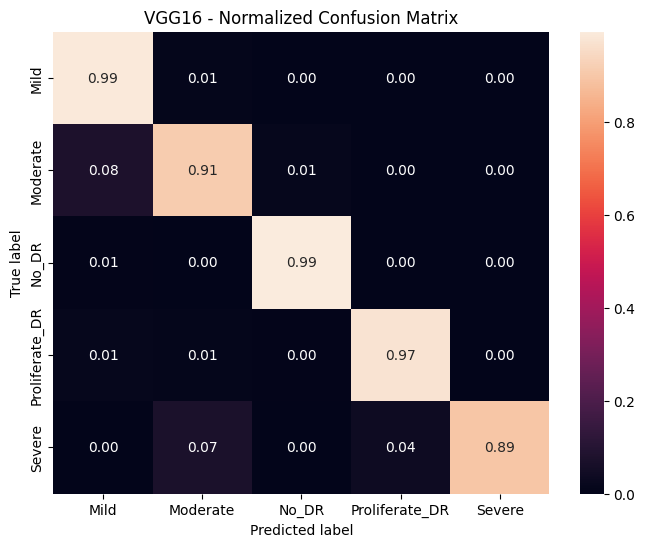

Performance (averaged across classes):
Rec (TPR avg)=  95.29653800034247
Spe (TNR avg)=  99.08263737641664
Pre (PPV avg)=  94.85445852818422
FPR avg=        0.9173626235833485
FNR avg=        4.703461999657527
NPV avg=        99.05974489878325
FDR avg=        5.14554147181579



ResNet50 Model Training Started ===>>>
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 75s 392ms/step - accuracy: 0.3213 - loss: 1.6197 - val_accuracy: 0.3169 - val_loss: 1.3980
Epoch 2/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 49s 305ms/step - accuracy: 0.4789 - loss: 1.3146 - val_accuracy: 0.7289 - val_loss: 0.9526
Epoch 3/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 83s 314ms/step - accuracy: 0.5937 - loss: 1.0603 - val_accuracy: 0.7993 - val_loss: 0.7724
Epoch 4/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 50s 313ms/step - accuracy: 0.6285 - loss: 0.9831 - val_accuracy: 0.6901 - val_loss: 0.7478
Epoch 5/50
160/160 ━━━━━━━━━━━━━━━━━━━━ 81s 310ms/step - accuracy: 0.6805 - loss: 0.8971 - val_accuracy: 0

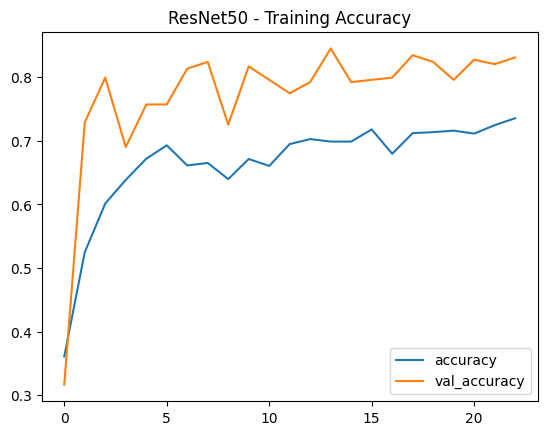

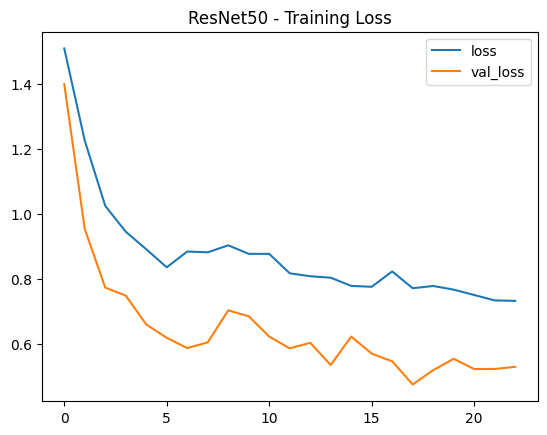



Accuracy on the test set: 84.25%
Accuracy: 0.84248
Precision: 0.83779
Recall: 0.84248
F1 Score: 0.83709
                precision    recall  f1-score   support

          Mild       0.84      0.84      0.84        94
      Moderate       0.74      0.49      0.59        79
         No_DR       0.94      0.99      0.97       187
Proliferate_DR       0.83      0.87      0.85       237
        Severe       0.75      0.77      0.76       114

      accuracy                           0.84       711
     macro avg       0.82      0.79      0.80       711
  weighted avg       0.84      0.84      0.84       711



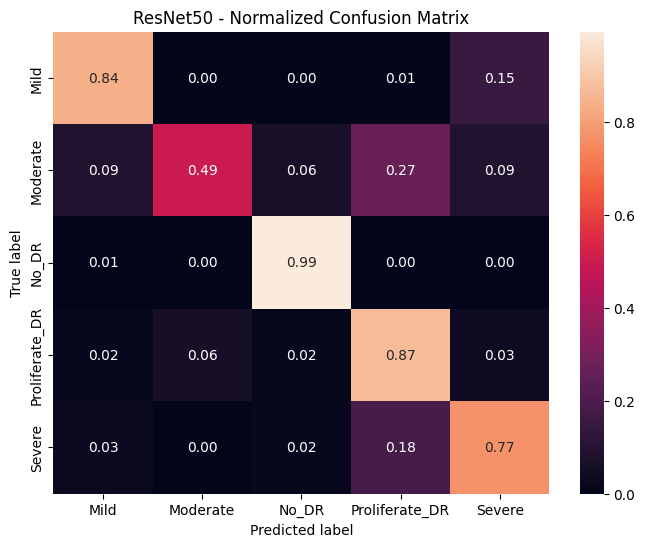

Performance (averaged across classes):
Rec (TPR avg)=  79.48192740976691
Spe (TNR avg)=  95.86502075451888
Pre (PPV avg)=  82.01147554407285
FPR avg=        4.134979245481131
FNR avg=        20.51807259023308
NPV avg=        96.08212104655513
FDR avg=        17.988524455927145




In [30]:
# -------------------------
# Train loop
# -------------------------

# 1. PASTE THE IMPORT HERE AT THE TOP
from tensorflow.keras.callbacks import EarlyStopping

for name, entry in models_info.items():
    print(f"\n{name} Model Training Started ===>>>")

    m = get_model(entry['model_fn'], num_classes=len(classes))
    models_info[name]['model'] = m

    # 2. PASTE THE EARLY STOPPING DEFINITION HERE (Inside the loop)
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    start = perf_counter()

    # 3. UPDATE THIS LINE TO USE 'epochs=50' AND ADD 'callbacks=[early_stop]'
    history = m.fit(
        train_images,
        validation_data=val_images,
        epochs=50,                  # Changed from 5 to 50
        callbacks=[early_stop],     # Added this
        verbose=1
    )

    duration = round(perf_counter() - start, 2)
    models_info[name]['perf'] = duration
    print(f"{name} trained in {duration} sec")

    models_info[name]['val_acc'] = [round(v,4) for v in history.history.get('val_accuracy', [])]
    models_info[name]['train_accuracy'] = [round(v,4) for v in history.history.get('accuracy', [])]

    results = m.evaluate(test_images, verbose=0)
    models_info[name]['test_accuracy'] = [round(results[1], 4) if len(results)>1 else None]

    # Plot training history
    pd.DataFrame(history.history)[['accuracy','val_accuracy']].plot()
    plt.title(f"{name} - Training Accuracy")
    plt.show()
    pd.DataFrame(history.history)[['loss','val_loss']].plot()
    plt.title(f"{name} - Training Loss")
    plt.show()

    print("\n\nAccuracy on the test set: {:.2f}%".format((results[1] if len(results)>1 else 0) * 100))

    # Predictions
    preds = m.predict(test_images, verbose=0)
    pred_indices = np.argmax(preds, axis=1)

    # Map indices to labels using class_indices from generator
    idx_to_label = {v:k for k,v in train_images.class_indices.items()}
    pred_labels = [idx_to_label[i] for i in pred_indices]

    # True labels from test_df (in the same order as test_images)
    y_test = list(test_df['Label'].values[:len(pred_labels)])

    # Basic metrics
    print('Accuracy:', np.round(metrics.accuracy_score(y_test, pred_labels),5))
    print('Precision:', np.round(metrics.precision_score(y_test, pred_labels, average='weighted', zero_division=0),5))
    print('Recall:', np.round(metrics.recall_score(y_test, pred_labels, average='weighted', zero_division=0),5))
    print('F1 Score:', np.round(metrics.f1_score(y_test, pred_labels, average='weighted', zero_division=0),5))
    print(classification_report(y_test, pred_labels, zero_division=0))

    # Confusion matrix (counts)
    cm_counts = sk_confusion_matrix(y_test, pred_labels, labels=sorted(set(y_test)))
    # normalized for display
    with np.errstate(all='ignore'):
        cm_norm = cm_counts.astype('float') / cm_counts.sum(axis=1)[:, np.newaxis]
        cm_norm = np.nan_to_num(cm_norm)

    plt.figure(figsize=(8,6))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', xticklabels=sorted(set(y_test)), yticklabels=sorted(set(y_test)))
    plt.title(f'{name} - Normalized Confusion Matrix')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

    # Compute common performance measures from counts (safe divisions)
    TP = np.diag(cm_counts).astype(float)
    FP = cm_counts.sum(axis=0).astype(float) - TP
    FN = cm_counts.sum(axis=1).astype(float) - TP
    TN = cm_counts.sum().astype(float) - (FP + FN + TP)

    # avoid division by zero
    def safe_div(a,b):
        return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=(b!=0))

    TPR = safe_div(TP, TP+FN)  # sensitivity / recall
    TNR = safe_div(TN, TN+FP)  # specificity
    PPV = safe_div(TP, TP+FP)  # precision
    NPV = safe_div(TN, TN+FN)
    FPR = safe_div(FP, FP+TN)
    FNR = safe_div(FN, TP+FN)
    FDR = safe_div(FP, TP+FP)

    from numpy import mean
    print("Performance (averaged across classes):")
    print("Rec (TPR avg)= ", mean(TPR)*100)
    print("Spe (TNR avg)= ", mean(TNR)*100)
    print("Pre (PPV avg)= ", mean(PPV)*100)
    print("FPR avg=       ", mean(FPR)*100)
    print("FNR avg=       ", mean(FNR)*100)
    print("NPV avg=       ", mean(NPV)*100)
    print("FDR avg=       ", mean(FDR)*100)
    print("\n")

Extracted Accuracy Data:
  Deep Learning Model  Accuracy
0         DenseNet201     97.47
1   InceptionResNetV2     94.37
2            Xception     94.51
3               VGG16     96.20
4            ResNet50     84.25




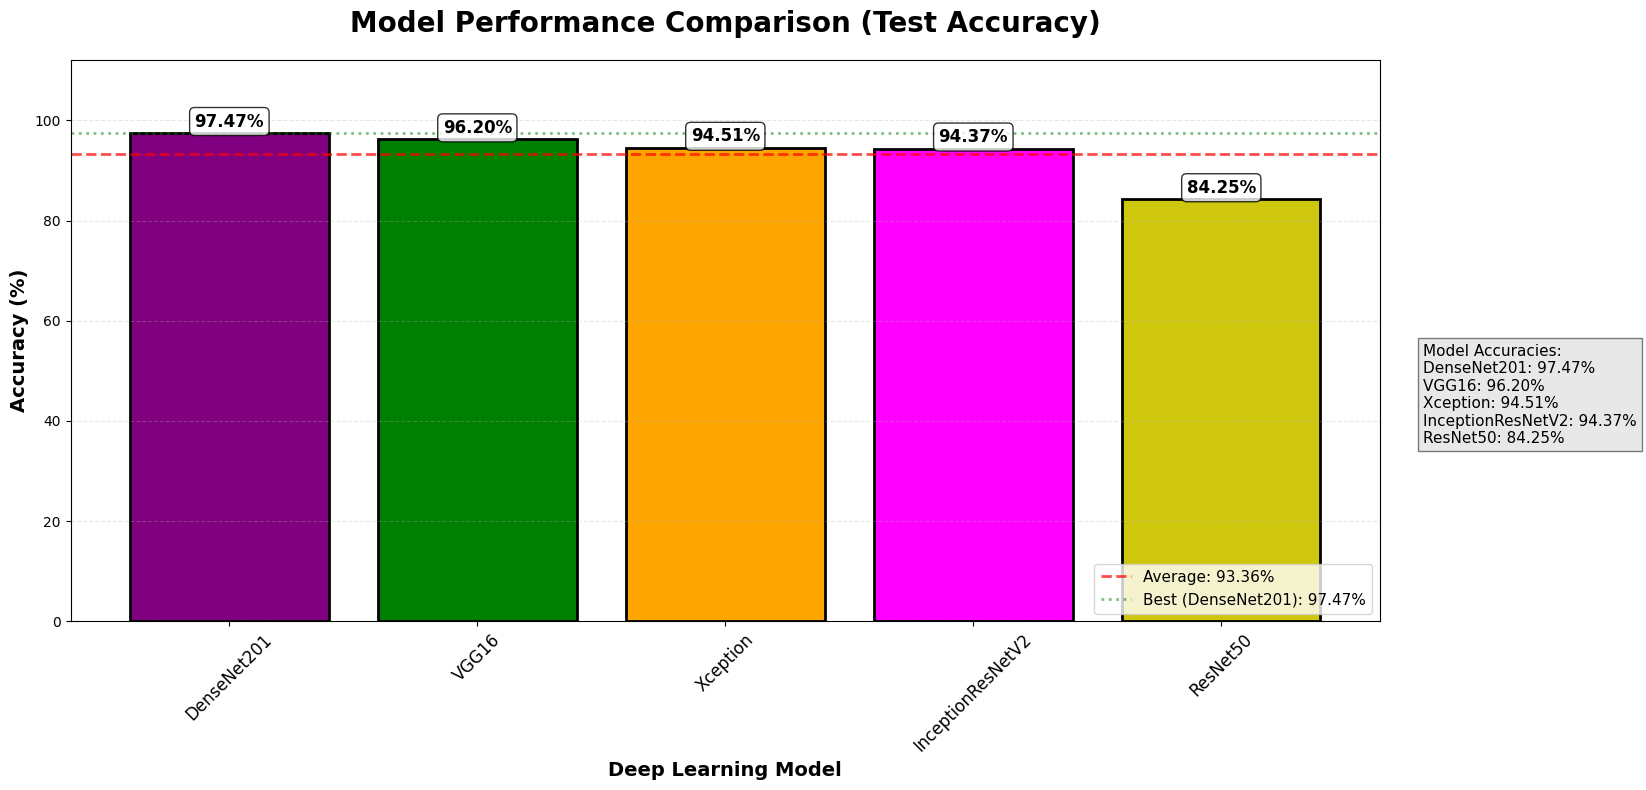


MODEL PERFORMANCE STATISTICS
Total Models Evaluated: 5
Highest Accuracy: 97.47% (DenseNet201)
Lowest Accuracy: 84.25% (ResNet50)
Average Accuracy: 93.36%
Standard Deviation: 5.25%


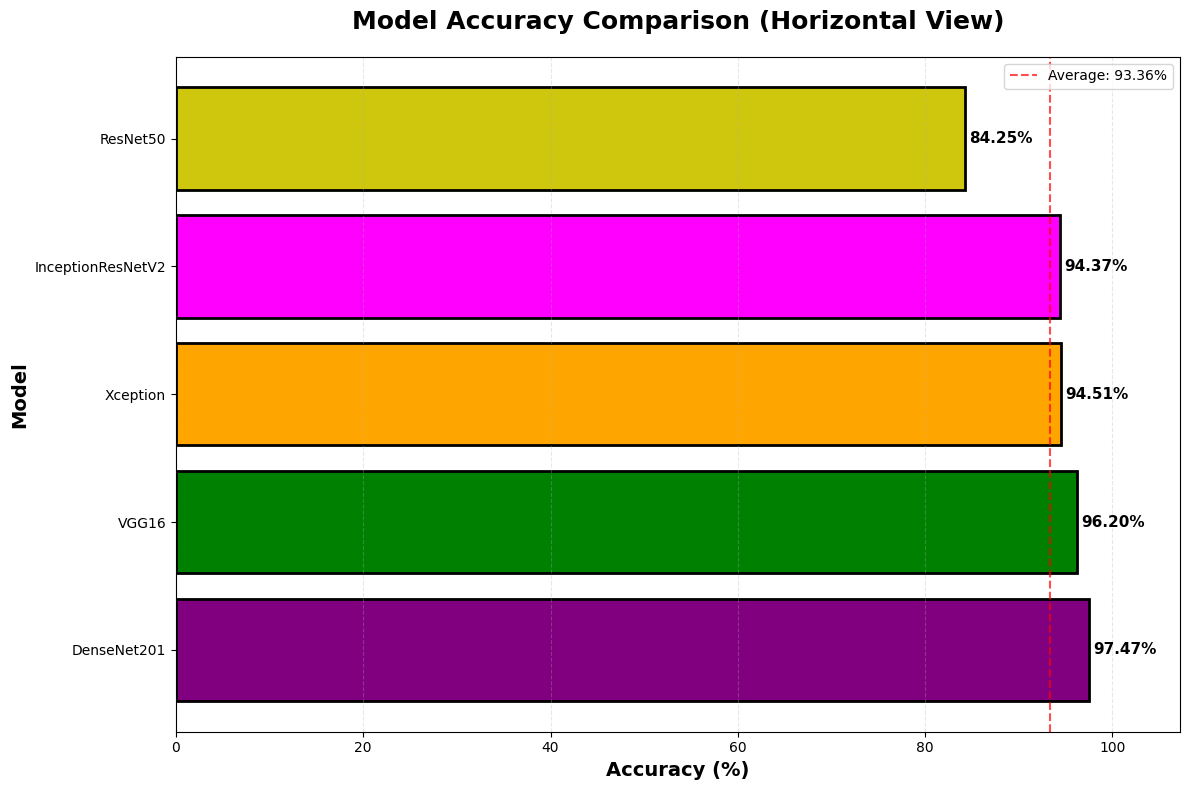

In [31]:
# ====================
# AUTO ACCURACY BAR CHART FROM MODELS_INFO
# ====================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Define colors for the bars
colors = ["purple", "green", "orange", "magenta", "#CFC60E", "#0FBBAE", "#87CEEB"]

# Extract accuracy values from models_info dictionary
model_names = []
accuracy_values = []

for name, entry in models_info.items():
    if 'test_accuracy' in entry and entry['test_accuracy']:
        model_names.append(name)
        # Get the accuracy value (handle if it's a list)
        acc = entry['test_accuracy']
        if isinstance(acc, list) and len(acc) > 0:
            accuracy_values.append(acc[0] * 100)  # Convert to percentage
        elif isinstance(acc, (int, float)):
            accuracy_values.append(acc * 100)
        else:
            accuracy_values.append(0)  # Default value if not available
    else:
        print(f"Warning: No test accuracy found for {name}")

# Create DataFrame
df = pd.DataFrame({
    'Deep Learning Model': model_names,
    'Accuracy': accuracy_values
})

print("Extracted Accuracy Data:")
print(df)
print("\n")

# Sort by accuracy (descending)
df = df.sort_values('Accuracy', ascending=False)

# Create bar plot
plt.figure(figsize=(14, 8))

# Create barplot with custom colors
bars = plt.bar(df['Deep Learning Model'], df['Accuracy'],
               color=colors[:len(df)], edgecolor='black', linewidth=2)

# Add percentage labels on top of each bar
for bar, acc in zip(bars, df['Accuracy']):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.5,
             f'{acc:.2f}%', ha='center', va='bottom',
             fontsize=12, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# Customize the plot
plt.title('Model Performance Comparison (Test Accuracy)',
          fontsize=20, fontweight='bold', pad=20)
plt.xlabel('Deep Learning Model', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy (%)', fontsize=14, fontweight='bold')
plt.ylim(0, max(df['Accuracy']) * 1.15)  # Add some space at the top

# Add grid for better readability
plt.grid(axis='y', alpha=0.3, linestyle='--')

# Rotate x-axis labels if needed
plt.xticks(rotation=45, fontsize=12)

# Add a horizontal line at average accuracy
avg_accuracy = df['Accuracy'].mean()
plt.axhline(y=avg_accuracy, color='red', linestyle='--', linewidth=2, alpha=0.7,
            label=f'Average: {avg_accuracy:.2f}%')

# Highlight the best model
best_model = df.iloc[0]
plt.axhline(y=best_model['Accuracy'], color='green', linestyle=':', linewidth=2, alpha=0.5,
            label=f'Best ({best_model["Deep Learning Model"]}): {best_model["Accuracy"]:.2f}%')

plt.legend(loc='lower right', fontsize=11)

# Add value table on the side
plt.figtext(1.02, 0.5,
            'Model Accuracies:\n' +
            '\n'.join([f'{row["Deep Learning Model"]}: {row["Accuracy"]:.2f}%'
                      for _, row in df.iterrows()]),
            fontsize=11, bbox=dict(facecolor='lightgray', alpha=0.5),
            verticalalignment='center')

plt.tight_layout()
plt.show()

# Display statistics
print("\n" + "="*60)
print("MODEL PERFORMANCE STATISTICS")
print("="*60)
print(f"Total Models Evaluated: {len(df)}")
print(f"Highest Accuracy: {df['Accuracy'].max():.2f}% ({df.iloc[0]['Deep Learning Model']})")
print(f"Lowest Accuracy: {df['Accuracy'].min():.2f}% ({df.iloc[-1]['Deep Learning Model']})")
print(f"Average Accuracy: {df['Accuracy'].mean():.2f}%")
print(f"Standard Deviation: {df['Accuracy'].std():.2f}%")
print("="*60)

# Also create a horizontal bar chart for alternative view
plt.figure(figsize=(12, 8))
bars_h = plt.barh(df['Deep Learning Model'], df['Accuracy'],
                  color=colors[:len(df)], edgecolor='black', linewidth=2)

# Add percentage labels
for bar, acc in zip(bars_h, df['Accuracy']):
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
             f'{acc:.2f}%', ha='left', va='center',
             fontsize=11, fontweight='bold')

plt.title('Model Accuracy Comparison (Horizontal View)',
          fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Accuracy (%)', fontsize=14, fontweight='bold')
plt.ylabel('Model', fontsize=14, fontweight='bold')
plt.xlim(0, max(df['Accuracy']) * 1.1)

# Add vertical line at average
plt.axvline(x=avg_accuracy, color='red', linestyle='--', alpha=0.7,
            label=f'Average: {avg_accuracy:.2f}%')

plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipython-input-213864610.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  p = sns.barplot(x='Deep Learning Model', y='Accuracy',data=df, palette=colors)
/tmp/ipython-input-213864610.py:13: UserWarning: The palette list has more values (7) than needed (5), which may not be intended.
  p = sns.barplot(x='Deep Learning Model', y='Accuracy',data=df, palette=colors)


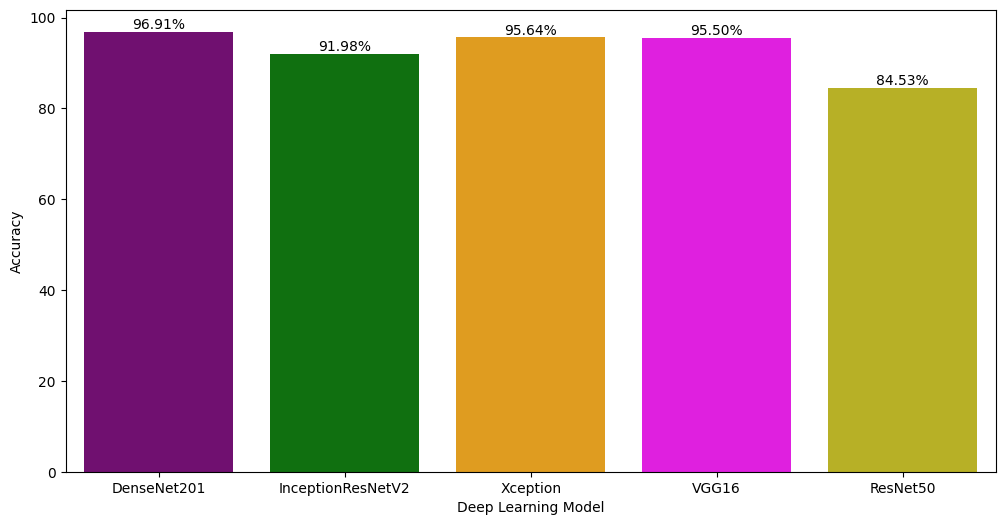

In [32]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

colors = ["purple", "green", "orange", "magenta","#CFC60E","#0FBBAE", "#87CEEB"]

df = pd.DataFrame(data=
{'Deep Learning Model':['DenseNet201', 'InceptionResNetV2', 'Xception' , 'VGG16', 'ResNet50'],
'Accuracy':[96.91, 91.98, 95.64, 95.50, 84.53]})

plt.figure(figsize=(12,6))

p = sns.barplot(x='Deep Learning Model', y='Accuracy',data=df, palette=colors)
for i in p.containers:
    labels = [f'{v.get_height():0.02f}%' for v in i]
    p.bar_label(i, labels=labels)

In [33]:
# ====================
# FINAL STEP: SAVE ALL MODELS
# ====================

print("\n" + "="*50)
print("SAVING ALL TRAINED MODELS AS .H5 FILES")
print("="*50)

for name, entry in models_info.items():
    if 'model' in entry and entry['model'] is not None:
        model_path = f"/content/drive/MyDrive/Defense/Final/FinalDataSet{name}_model.h5"
        entry['model'].save(model_path)
        print(f"✅ Saved: {model_path}")
    else:
        print(f"⚠️  Model '{name}' not found or not trained.")

print("\n🎉 All models saved successfully in Google Drive!")


SAVING ALL TRAINED MODELS AS .H5 FILES


✅ Saved: /content/drive/MyDrive/Defense/Final/FinalDataSetDenseNet201_model.h5


✅ Saved: /content/drive/MyDrive/Defense/Final/FinalDataSetInceptionResNetV2_model.h5


✅ Saved: /content/drive/MyDrive/Defense/Final/FinalDataSetXception_model.h5


✅ Saved: /content/drive/MyDrive/Defense/Final/FinalDataSetVGG16_model.h5
✅ Saved: /content/drive/MyDrive/Defense/Final/FinalDataSetResNet50_model.h5

🎉 All models saved successfully in Google Drive!
